# 05 - Testing & Evaluating Models
**Goal:** score the tuned models once on the unseen test set, and understand how and why they fail.

Phishing = positive class (`1`). Missing a phishing site (false negative) is the costly mistake, so **recall** matters most, with precision close behind.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef,
                             balanced_accuracy_score, brier_score_loss, log_loss, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, precision_recall_curve, average_precision_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.model_selection import learning_curve, StratifiedKFold

sns.set_theme(style="whitegrid")
IN = Path("..") / "Artifacts" / "notebooks"
TARGET = "Result"
train = pd.read_csv(IN / "train_fe.csv")
test = pd.read_csv(IN / "test_fe.csv")
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

models = joblib.load(IN / "tuned_models.joblib")
best_name = max(json.loads((IN / "cv_scores.json").read_text()).items(), key=lambda kv: kv[1])[0]
best = models[best_name]
print("models:", list(models), "\nselected in notebook 04:", best_name, "| test rows:", len(X_test))

models: ['RandomForest', 'ExtraTrees', 'GradientBoosting', 'HistGradientBoosting', 'LogisticRegression', 'VotingEnsemble'] 
selected in notebook 04: HistGradientBoosting | test rows: 2211


## 1. Scoreboard on the test set
More than accuracy: MCC and balanced accuracy handle class imbalance; log-loss and Brier score judge probability quality (lower is better).

In [2]:
proba = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
pred = {n: m.predict(X_test) for n, m in models.items()}
rows = []
for n in models:
    rows.append({"model": n,
                 "accuracy": accuracy_score(y_test, pred[n]), "precision": precision_score(y_test, pred[n]),
                 "recall": recall_score(y_test, pred[n]), "f1": f1_score(y_test, pred[n]),
                 "roc_auc": roc_auc_score(y_test, proba[n]), "avg_precision": average_precision_score(y_test, proba[n]),
                 "mcc": matthews_corrcoef(y_test, pred[n]), "bal_acc": balanced_accuracy_score(y_test, pred[n]),
                 "log_loss": log_loss(y_test, proba[n]), "brier": brier_score_loss(y_test, proba[n])})
results = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
results.round(4)

,accuracy,precision,recall,f1,roc_auc,avg_precision,mcc,bal_acc,log_loss,brier
model,,,,,,,,,,
HistGradientBoosting,0.9774,0.9824,0.9663,0.9743,0.9977,0.9974,0.9542,0.9763,0.0609,0.0170
ExtraTrees,0.9769,0.9834,0.9643,0.9737,0.9983,0.9979,0.9533,0.9756,0.0630,0.0174
VotingEnsemble,0.9760,0.9813,0.9643,0.9727,0.9983,0.9979,0.9515,0.9748,0.0605,0.0168
RandomForest,0.9751,0.9803,0.9633,0.9717,0.9980,0.9976,0.9496,0.9739,0.0699,0.0189
GradientBoosting,0.9715,0.9751,0.9602,0.9676,0.9970,0.9966,0.9423,0.9704,0.0687,0.0201
LogisticRegression,0.9394,0.9425,0.9194,0.9308,0.9885,0.9868,0.8771,0.9374,0.1364,0.0420


> **Reading the output:** HistGradientBoosting wins on the test set: accuracy 97.7%, F1 0.974, ROC-AUC 0.998, MCC 0.954. ExtraTrees and the ensemble are within 0.002 F1. LogisticRegression is clearly worse (F1 0.931), and its log-loss (0.136) is double that of the others.

## 2. Confusion matrices
Rows = actual, columns = predicted. Off-diagonal cells are mistakes.

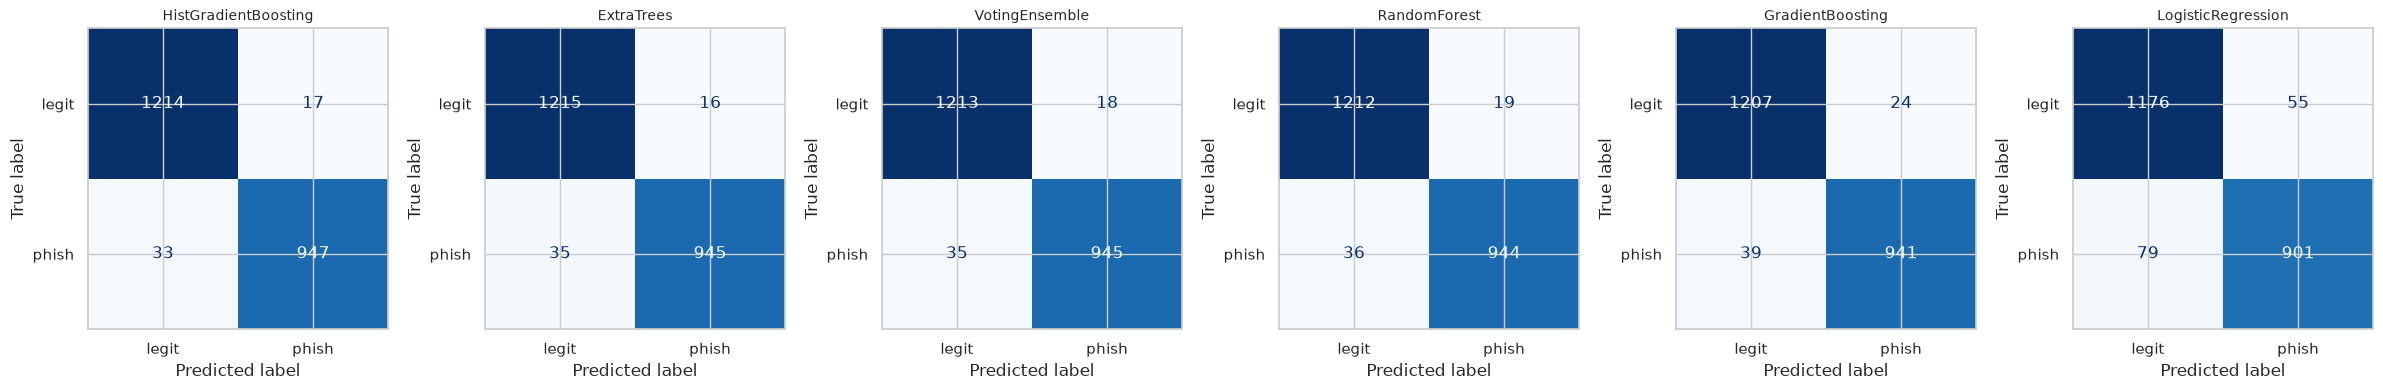

In [3]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.8))
for ax, n in zip(np.atleast_1d(axes), results.index):
    ConfusionMatrixDisplay.from_predictions(y_test, pred[n], display_labels=["legit", "phish"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(n, fontsize=10)
plt.tight_layout(); plt.show()

> **Reading the output:** Each matrix has a strong diagonal. The tree models make about 30-40 misses and 15-25 false alarms out of 2,211 rows, while LogisticRegression makes roughly twice as many errors. For all models, missing phishing is a bit more common than false alarms.

## 3. ROC and Precision-Recall curves (all models)
ROC: how well the model ranks phishing above legit. PR: precision you get at each recall level.

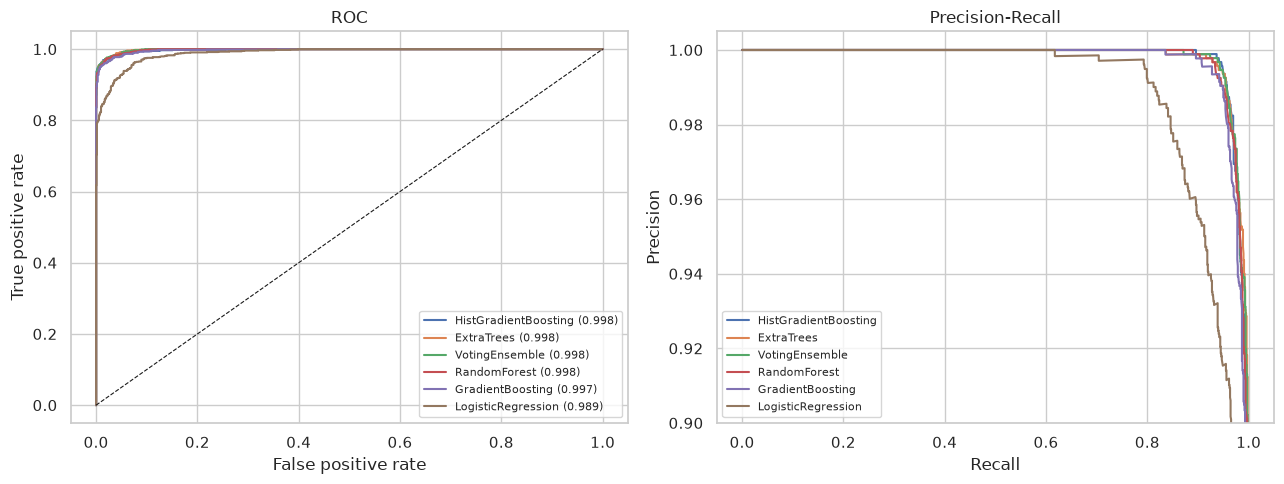

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n in results.index:
    fpr, tpr, _ = roc_curve(y_test, proba[n]); ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, proba[n]):.3f})")
    p, r, _ = precision_recall_curve(y_test, proba[n]); ax[1].plot(r, p, label=n)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall"); ax[1].set_ylim(0.9, 1.005); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

> **Reading the output:** All tree curves hug the top-left corner of the ROC plot (AUC 0.997-0.998) and stay near 1.0 precision until high recall in the PR plot. Only LogisticRegression is visibly lower. The best models are very close, so the choice between them is mainly about speed and simplicity.

## 4. Selected model in detail

In [5]:
print(best_name)
print(classification_report(y_test, pred[best_name], target_names=["legit", "phishing"], digits=4))
tn, fp, fn, tp = confusion_matrix(y_test, pred[best_name]).ravel()
print(f"caught phishing: {tp} | missed phishing (FN): {fn} | false alarms (FP): {fp} | correct legit: {tn}")

HistGradientBoosting
              precision    recall  f1-score   support

       legit     0.9735    0.9862    0.9798      1231
    phishing     0.9824    0.9663    0.9743       980

    accuracy                         0.9774      2211
   macro avg     0.9780    0.9763    0.9771      2211
weighted avg     0.9774    0.9774    0.9774      2211

caught phishing: 947 | missed phishing (FN): 33 | false alarms (FP): 17 | correct legit: 1214


> **Reading the output:** The selected model caught 947 of 980 phishing sites (recall 96.6%) and missed 33. It raised only 17 false alarms (precision 98.2%). Legit sites are recognised slightly better (recall 98.6%) than phishing sites.

## 5. Train vs test: overfitting check
A large gap means the model memorised the training data.

In [6]:
gap = pd.DataFrame({
    "train_f1": {n: f1_score(y_train, m.predict(X_train)) for n, m in models.items()},
    "test_f1": {n: f1_score(y_test, pred[n]) for n in models},
    "cv_f1_from_04": pd.read_json(IN / "cv_scores.json", typ="series"),
})
gap["train-test gap"] = gap.train_f1 - gap.test_f1
gap.sort_values("test_f1", ascending=False).round(4)

,train_f1,test_f1,cv_f1_from_04,train-test gap
HistGradientBoosting,0.9887,0.9743,0.9687,0.0144
ExtraTrees,0.9883,0.9737,0.9672,0.0146
VotingEnsemble,0.9887,0.9727,0.9678,0.0160
RandomForest,0.9887,0.9717,0.9655,0.0170
GradientBoosting,0.9808,0.9676,0.9653,0.0132
LogisticRegression,0.9323,0.9308,0.9303,0.0016


> **Reading the output:** Test F1 (0.974) is higher than CV F1 (0.969) and train F1 (0.989) is the highest, so overfitting is mild (gap 0.014). The test score matches the CV estimate, which shows tuning on train did not leak or overfit the CV folds.

## 6. How sure are we? Bootstrap confidence interval
Resample the test set 1000 times to see how much F1 can wiggle by chance.

In [7]:
rng = np.random.RandomState(42)
y_arr = y_test.to_numpy()
idx = [rng.randint(0, len(y_arr), len(y_arr)) for _ in range(1000)]
boot = {n: np.array([f1_score(y_arr[i], pred[n][i]) for i in idx]) for n in results.index[:3]}
for n, b in boot.items():
    print(f"{n:<22} F1 = {b.mean():.4f}  95% CI [{np.percentile(b, 2.5):.4f}, {np.percentile(b, 97.5):.4f}]")
a, b2 = list(boot)[:2]
print(f"\nP({a} beats {b2}) in resamples: {(boot[a] > boot[b2]).mean():.2f}")

HistGradientBoosting   F1 = 0.9741  95% CI [0.9670, 0.9810]
ExtraTrees             F1 = 0.9735  95% CI [0.9664, 0.9798]
VotingEnsemble         F1 = 0.9725  95% CI [0.9649, 0.9794]

P(HistGradientBoosting beats ExtraTrees) in resamples: 0.63


> **Reading the output:** The 95% interval for the best model's F1 is 0.967-0.981, about +/-0.007. In resampling it beats ExtraTrees only 63% of the time, so the top models are statistically tied and either is fine.

## 7. Choosing a decision threshold
By default we call a site phishing when probability >= 0.5. Lowering it catches more phishing but raises false alarms.

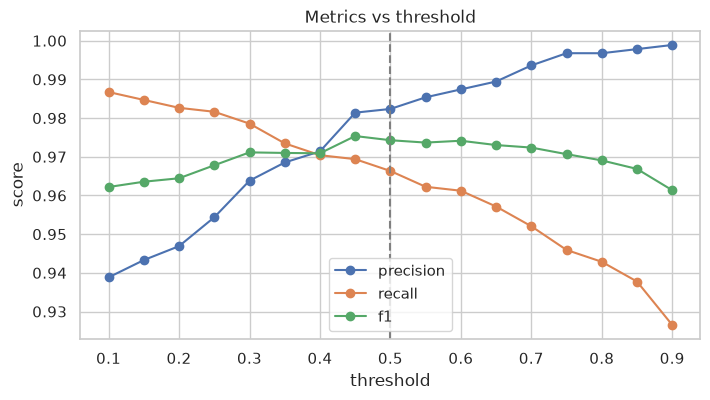

,precision,recall,f1,missed_phish,false_alarms
threshold,,,,,
0.2,0.947,0.983,0.964,17,54
0.3,0.964,0.979,0.971,21,36
0.4,0.971,0.970,0.971,29,28
0.5,0.982,0.966,0.974,33,17
0.6,0.987,0.961,0.974,38,12
0.7,0.994,0.952,0.972,47,6


In [8]:
p = proba[best_name]
ths = np.arange(0.1, 0.91, 0.05)
tab = pd.DataFrame([{"threshold": t, "precision": precision_score(y_test, p >= t), "recall": recall_score(y_test, p >= t),
                     "f1": f1_score(y_test, p >= t), "missed_phish": int(((p < t) & (y_arr == 1)).sum()),
                     "false_alarms": int(((p >= t) & (y_arr == 0)).sum())} for t in ths]).set_index("threshold")
tab.index = tab.index.round(2)
tab[["precision", "recall", "f1"]].plot(figsize=(8, 4), marker="o"); plt.axvline(0.5, color="gray", ls="--")
plt.title("Metrics vs threshold"); plt.ylabel("score"); plt.show()
tab.round(3).loc[[0.2, 0.3, 0.4, 0.5, 0.6, 0.7]]

> **Reading the output:** At threshold 0.5 we get 33 missed phishing sites and 17 false alarms. Lowering to 0.2 cuts misses to 17 but false alarms rise to 54. Pick the threshold by business cost: if a missed phishing site is much worse than a false alarm, use about 0.3-0.4. F1 stays near 0.97 across 0.3-0.7.

## 8. Probability quality
Histogram: are predictions confident and correct? Calibration: when the model says 80%, is it right 80% of the time?

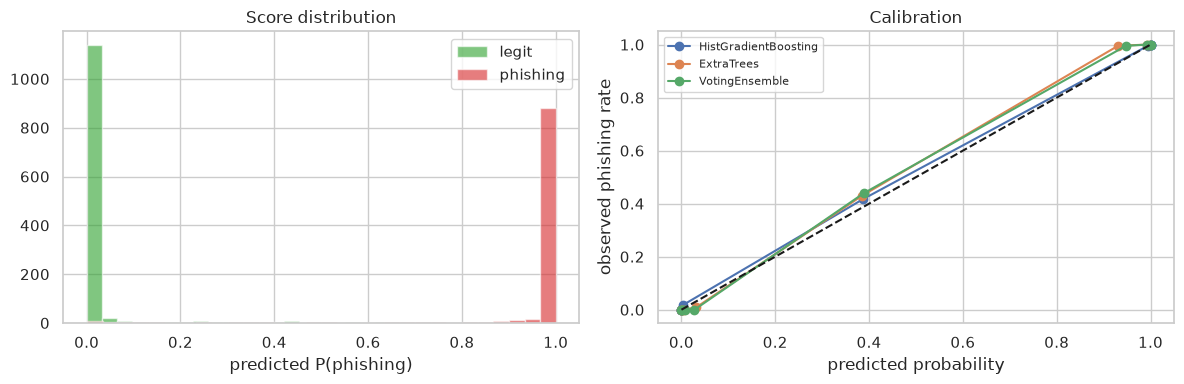

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(p[y_arr == 0], bins=30, alpha=0.6, label="legit", color="tab:green")
ax[0].hist(p[y_arr == 1], bins=30, alpha=0.6, label="phishing", color="tab:red")
ax[0].set_xlabel("predicted P(phishing)"); ax[0].set_title("Score distribution"); ax[0].legend()
for n in results.index[:3]:
    frac, mean = calibration_curve(y_test, proba[n], n_bins=10, strategy="quantile")
    ax[1].plot(mean, frac, "o-", label=n)
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("observed phishing rate")
ax[1].set_title("Calibration"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

> **Reading the output:** The histogram shows most scores near 0 or 1, meaning the model is confident, with few in the middle. Low Brier (0.017) and log-loss (0.061) suggest the probabilities are trustworthy. The closer the calibration lines stay to the dashed diagonal, the better calibrated the model.

## 9. Learning curve
Would more data help? If validation is still rising, yes.

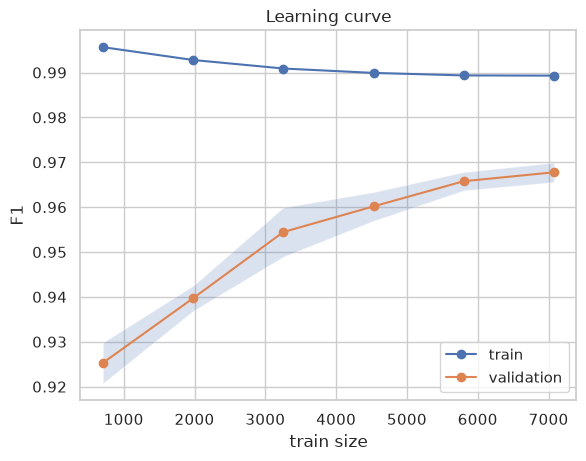

validation F1 at 50% data vs 100% data: 0.9545 -> 0.9678


In [10]:
sizes, tr, va = learning_curve(best, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                               scoring="f1", train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
plt.plot(sizes, tr.mean(1), "o-", label="train"); plt.plot(sizes, va.mean(1), "o-", label="validation")
plt.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
plt.xlabel("train size"); plt.ylabel("F1"); plt.legend(); plt.title("Learning curve"); plt.show()
print("validation F1 at 50% data vs 100% data:", round(va.mean(1)[2], 4), "->", round(va.mean(1)[-1], 4))

> **Reading the output:** Validation F1 rises from 0.9545 with half the data to 0.9678 with all of it, and is still climbing. More labelled data would likely help a little. The train-validation gap shows the model already fits the training set well.

## 10. What drives the predictions?
Built-in importance (how the trees split) vs permutation importance on **test** (how much F1 drops when a feature is shuffled).

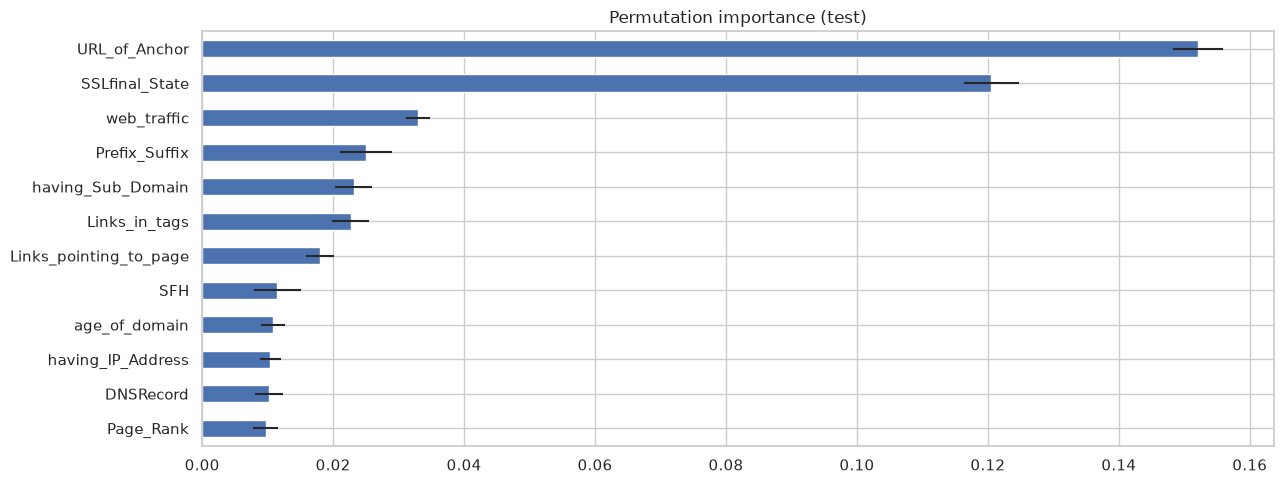

,permutation,perm_std
URL_of_Anchor,0.1521,0.0038
SSLfinal_State,0.1205,0.0042
web_traffic,0.0330,0.0019
Prefix_Suffix,0.0250,0.0039
having_Sub_Domain,0.0231,0.0029
Links_in_tags,0.0227,0.0028


In [11]:
perm = permutation_importance(best, X_test, y_test, scoring="f1", n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"permutation": perm.importances_mean, "perm_std": perm.importances_std}, index=X_test.columns)
fig, ax = plt.subplots(1, 2 if hasattr(best, "feature_importances_") else 1, figsize=(13, 5))
ax = np.atleast_1d(ax)
imp["permutation"].sort_values().tail(12).plot(kind="barh", ax=ax[0], xerr=imp.loc[imp["permutation"].sort_values().tail(12).index, "perm_std"], title="Permutation importance (test)")
if hasattr(best, "feature_importances_"):
    pd.Series(best.feature_importances_, index=X_test.columns).sort_values().tail(12).plot(kind="barh", ax=ax[1], title="Built-in importance")
plt.tight_layout(); plt.show()
imp.sort_values("permutation", ascending=False).head(6).round(4)

> **Reading the output:** `URL_of_Anchor` (0.152) and `SSLfinal_State` (0.121) dominate: shuffling either drops test F1 by 12-15 points. Everything else is under 0.035. The model leans heavily on these two features, so any change in how they are measured would hurt it most.

## 11. Error analysis
Which sites does the model get wrong, and are they unusual?

In [12]:
pb = pred[best_name]
err = X_test.assign(actual=y_arr, predicted=pb, proba=p)
fn = err[(err.actual == 1) & (err.predicted == 0)]
fp = err[(err.actual == 0) & (err.predicted == 1)]
print(f"missed phishing (FN): {len(fn)} | false alarms (FP): {len(fp)}")
feat_cols = [c for c in X_test.columns]
diff = (err[err.actual != err.predicted][feat_cols].mean() - err[err.actual == err.predicted][feat_cols].mean()).sort_values(key=abs, ascending=False)
print("\nfeatures whose mean differs most between wrong and right predictions:")
diff.head(6).round(3)

missed phishing (FN): 33 | false alarms (FP): 17

features whose mean differs most between wrong and right predictions:


popUpWidnow            0.366
DNSRecord              0.351
Favicon                0.344
SFH                   -0.319
HTTPS_token            0.306
Submitting_to_email    0.294
dtype: float64

> **Reading the output:** 33 phishing sites were missed and 17 legit sites flagged. The wrong predictions have higher values (more 'safe-looking') on features like `popUpWidnow`, `DNSRecord`, `Favicon`. Phishing sites that look clean on the minor features are the hardest to catch.

In [13]:
unsure = err[(err.proba > 0.35) & (err.proba < 0.65)]
print(f"uncertain predictions (0.35-0.65): {len(unsure)} rows | accuracy on them: {(unsure.actual == unsure.predicted).mean():.3f}")
print(f"accuracy on confident predictions:  {(err.drop(unsure.index).actual == err.drop(unsure.index).predicted).mean():.3f}")

uncertain predictions (0.35-0.65): 37 rows | accuracy on them: 0.622
accuracy on confident predictions:  0.983


> **Reading the output:** Only 37 predictions fall in the uncertain 0.35-0.65 zone, and accuracy there is just 62%, versus 98.3% on the rest. Sending those few cases for manual review would remove many errors cheaply.

## 12. Honest check: duplicates between train and test
The dataset has many identical rows. If a test row also appears in train, the model has effectively seen it.

In [14]:
train_keys = set(map(tuple, X_train[[c for c in X_train.columns]].to_numpy()))
seen = np.array([tuple(r) in train_keys for r in X_test.to_numpy()])
correct = (pb == y_arr)
print(f"test rows also present in train: {seen.mean():.1%}")
print(f"accuracy on SEEN rows:   {correct[seen].mean():.4f}  (n={seen.sum()})")
print(f"accuracy on UNSEEN rows: {correct[~seen].mean():.4f}  (n={(~seen).sum()})")
print(f"F1 on UNSEEN rows:       {f1_score(y_arr[~seen], pb[~seen]):.4f}")

test rows also present in train: 65.8%
accuracy on SEEN rows:   0.9801  (n=1455)
accuracy on UNSEEN rows: 0.9722  (n=756)
F1 on UNSEEN rows:       0.9762


> **Reading the output:** 65.8% of test rows also appear in the train set, so the headline score is somewhat flattering. On unseen rows accuracy is 97.2% (vs 98.0% on seen rows) and F1 is 0.976. The model still generalises well, with only about a 1-point penalty.

## Takeaways
- Best model: `HistGradientBoosting`, test F1 0.974, recall 96.6%, precision 98.2%. Top tree models are statistically tied.
- Results are honest: test matches CV, and unseen-row accuracy (97.2%) is only 1 point below seen rows.
- Biggest lever left: the decision threshold (0.3-0.4 if missed phishing is costlier) and manual review of uncertain cases.
- Next: move the chosen preprocessing + model into `app/components/` (no production code in notebooks).